## Bibliotecas

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress
from pathlib import Path

## Configurações e Carga dos Dados


In [2]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "processed" / "dados_consolidados.parquet"
FIGURES_DIR = BASE_DIR / "figures" / "calibracao"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_PATH)
df['Amostra'] = df['Amostra'].replace({'sst_4': 'sst'})

ordem_amostras = ['vazio', 'agua', 'sst', '1_5', '1_4']
df['Amostra'] = pd.Categorical(df['Amostra'], categories=ordem_amostras, ordered=True)

print("Dados prontos para calibração. Amostras ordenadas:", ordem_amostras)

Dados prontos para calibração. Amostras ordenadas: ['vazio', 'agua', 'sst', '1_5', '1_4']


## Agrupamentos e Comparação Diária vs. Rodadas

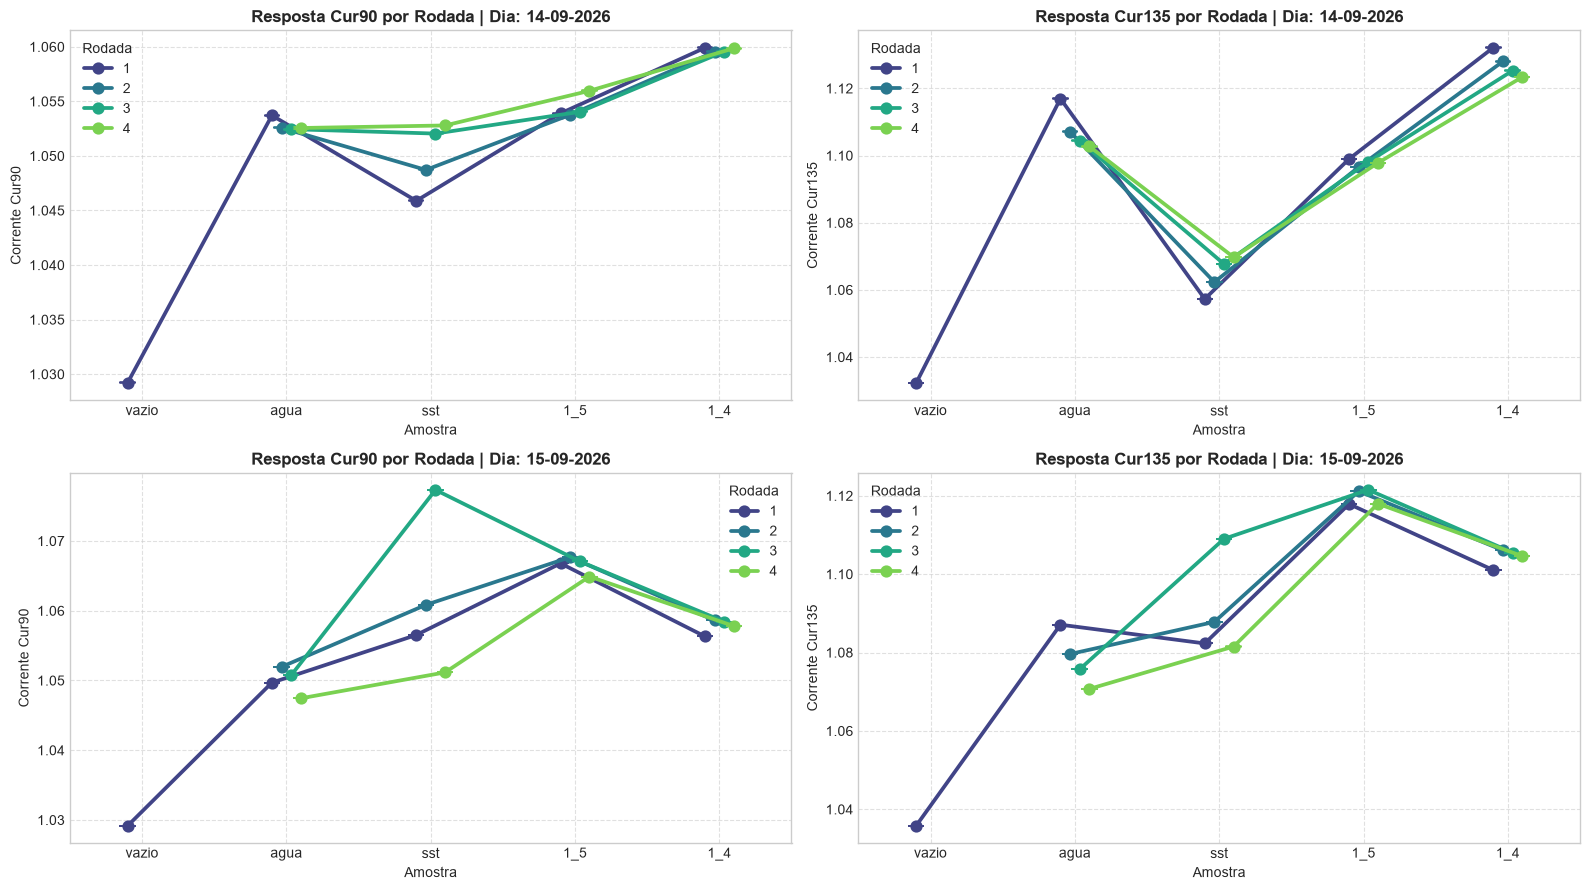

In [3]:
dias = df['Dia'].unique()
n_dias = len(dias)

# Cria uma linha no subplot para cada dia
fig, axes = plt.subplots(n_dias, 2, figsize=(16, 4.5 * n_dias), sharey=False)

# Garante que 'axes' seja bidimensional mesmo se houver apenas 1 dia
if n_dias == 1:
    axes = np.array([axes])

for idx, dia in enumerate(dias):
    df_dia = df[df['Dia'] == dia].copy()
    
    # Subplot Cur90 para o dia atual
    sns.pointplot(
        data=df_dia, x='Amostra', y='Cur90', hue='Rodada', ax=axes[idx, 0],
        capsize=0.1, err_kws={'linewidth': 1.2}, palette='viridis', dodge=0.2
    )
    axes[idx, 0].set_title(f'Resposta Cur90 por Rodada | Dia: {dia}', fontweight='bold', fontsize=12)
    axes[idx, 0].set_ylabel('Corrente Cur90')
    axes[idx, 0].grid(True, linestyle='--', alpha=0.6)
    
    # Subplot Cur135 para o dia atual
    sns.pointplot(
        data=df_dia, x='Amostra', y='Cur135', hue='Rodada', ax=axes[idx, 1],
        capsize=0.1, err_kws={'linewidth': 1.2}, palette='viridis', dodge=0.2
    )
    axes[idx, 1].set_title(f'Resposta Cur135 por Rodada | Dia: {dia}', fontweight='bold', fontsize=12)
    axes[idx, 1].set_ylabel('Corrente Cur135')
    axes[idx, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparativo_por_rodada_por_dia.png", dpi=300, bbox_inches='tight')
plt.show()

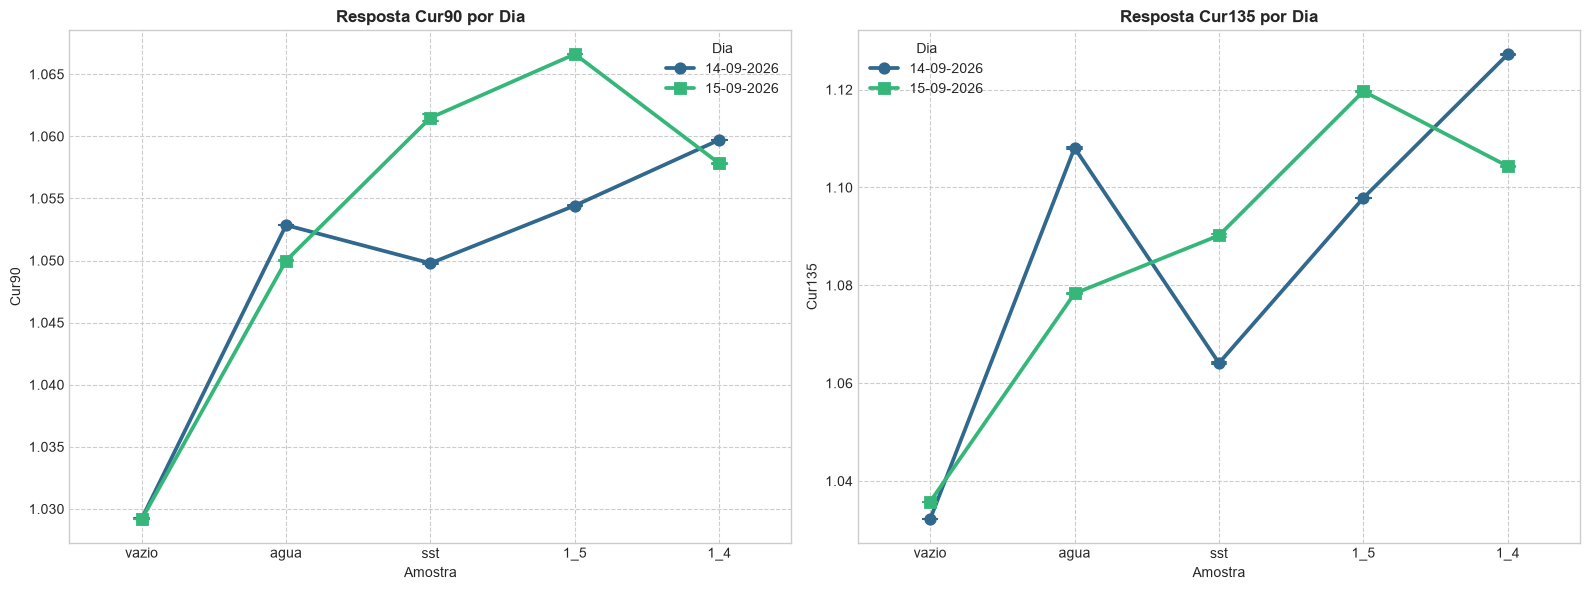

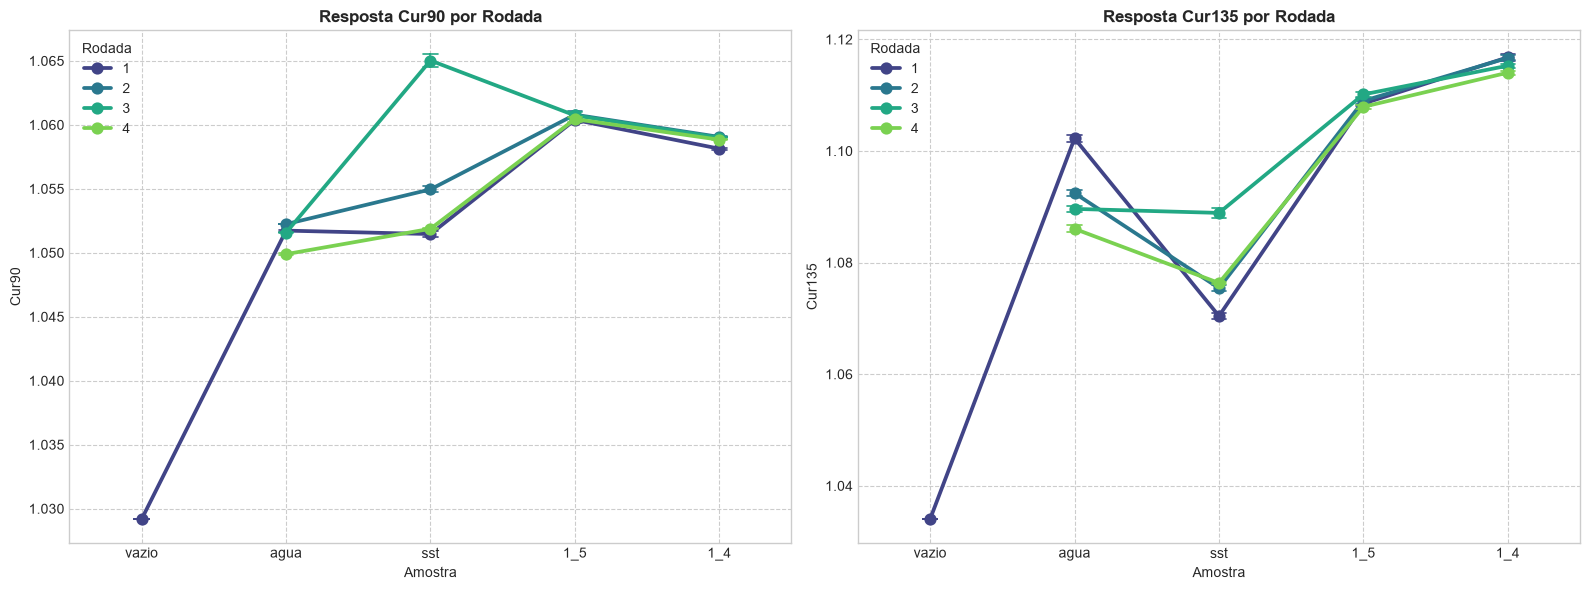

In [4]:
# 1. Comparativo por Dia de Medição
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.pointplot(
    data=df, x='Amostra', y='Cur90', hue='Dia', ax=axes[0],
    capsize=0.1, err_kws={'linewidth': 1.5}, markers=['o', 's'], palette='viridis'
)
axes[0].set_title('Resposta Cur90 por Dia', fontweight='bold')
axes[0].grid(True, linestyle='--')

sns.pointplot(
    data=df, x='Amostra', y='Cur135', hue='Dia', ax=axes[1],
    capsize=0.1, err_kws={'linewidth': 1.5}, markers=['o', 's'], palette='viridis'
)
axes[1].set_title('Resposta Cur135 por Dia', fontweight='bold')
axes[1].grid(True, linestyle='--')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparativo_por_dia.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. Comparativo por Rodada
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.pointplot(
    data=df, x='Amostra', y='Cur90', hue='Rodada', ax=axes[0],
    capsize=0.1, err_kws={'linewidth': 1.2}, palette='viridis'
)
axes[0].set_title('Resposta Cur90 por Rodada', fontweight='bold')
axes[0].grid(True, linestyle='--')

sns.pointplot(
    data=df, x='Amostra', y='Cur135', hue='Rodada', ax=axes[1],
    capsize=0.1, err_kws={'linewidth': 1.2}, palette='viridis'
)
axes[1].set_title('Resposta Cur135 por Rodada', fontweight='bold')
axes[1].grid(True, linestyle='--')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparativo_por_rodada.png", dpi=300, bbox_inches='tight')
plt.show()

## Curva de Calibração Geral

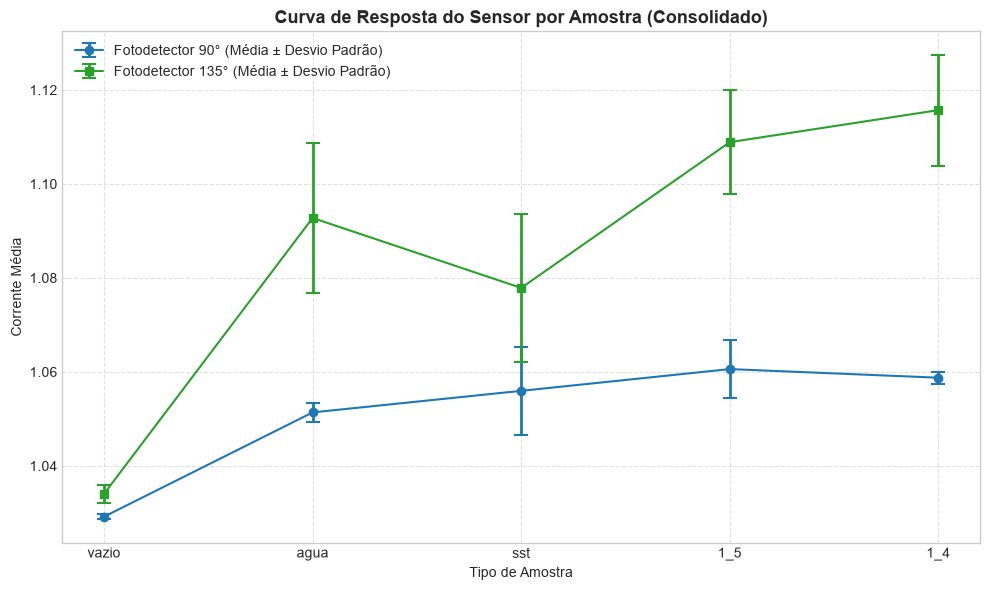

In [5]:
# Agrupamento estatístico
df_stats = df.groupby('Amostra', observed=False).agg(
    mean_90=('Cur90', 'mean'),
    std_90=('Cur90', 'std'),
    mean_135=('Cur135', 'mean'),
    std_135=('Cur135', 'std')
).reset_index()

fig, ax = plt.subplots(figsize=(10, 6))

# Pontos com barras de erro - 90 Graus
ax.errorbar(
    x=df_stats['Amostra'], y=df_stats['mean_90'], yerr=df_stats['std_90'],
    fmt='-o', color='tab:blue', ecolor='tab:blue', elinewidth=2, capsize=5, capthick=1.5,
    label='Fotodetector 90° (Média ± Desvio Padrão)'
)

# Pontos com barras de erro - 135 Graus
ax.errorbar(
    x=df_stats['Amostra'], y=df_stats['mean_135'], yerr=df_stats['std_135'],
    fmt='-s', color='tab:green', ecolor='tab:green', elinewidth=2, capsize=5, capthick=1.5,
    label='Fotodetector 135° (Média ± Desvio Padrão)'
)

ax.set_title('Curva de Resposta do Sensor por Amostra (Consolidado)', fontsize=13, fontweight='bold')
ax.set_xlabel('Tipo de Amostra')
ax.set_ylabel('Corrente Média')
ax.legend(loc='best')
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "curva_calibracao_consolidação_errorbar.png", dpi=300, bbox_inches='tight')
plt.show()

## Distribuição dos Sinais

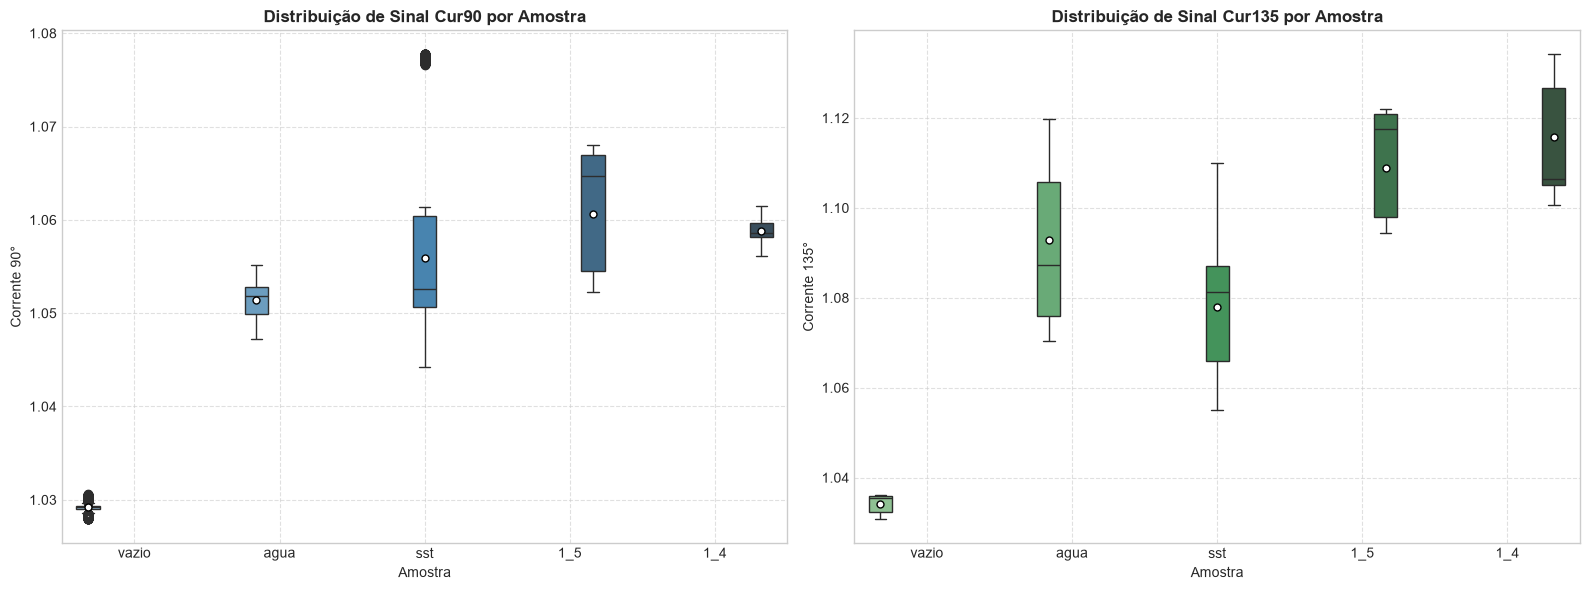

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot Cur90
sns.boxplot(
    data=df, x='Amostra', y='Cur90', ax=axes[0], 
    palette='Blues_d', showmeans=True,
    hue='Amostra', meanprops={"marker":"o","markerfacecolor":"white","markeredgecolor":"black","markersize":"5"}
)
axes[0].set_title('Distribuição de Sinal Cur90 por Amostra', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Corrente 90°')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Boxplot Cur135
sns.boxplot(
    data=df, x='Amostra', y='Cur135', ax=axes[1], 
    palette='Greens_d', showmeans=True,
    hue='Amostra', meanprops={"marker":"o","markerfacecolor":"white","markeredgecolor":"black","markersize":"5"}
)
axes[1].set_title('Distribuição de Sinal Cur135 por Amostra', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Corrente 135°')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "boxplot_distribuicao_amostras.png", dpi=300, bbox_inches='tight')
plt.show()

## Cálculo dos Sinais Combinados

In [7]:
# Evita divisão por zero adicionando um valor infinitesimal se necessário
eps = 1e-9

# 1. Razão de Espalhamento (Ratio)
df['Ratio_90_135'] = df['Cur90'] / (df['Cur135'] + eps)

# 2. Índice de Diferença Normalizada (NDI)
df['NDI'] = (df['Cur90'] - df['Cur135']) / (df['Cur90'] + df['Cur135'] + eps)

# 3. Normalização Min-Max dos sinais brutos (para plotar no mesmo eixo)
df['Cur90_norm'] = (df['Cur90'] - df['Cur90'].min()) / (df['Cur90'].max() - df['Cur90'].min())
df['Cur135_norm'] = (df['Cur135'] - df['Cur135'].min()) / (df['Cur135'].max() - df['Cur135'].min())

print("Métricas combinadas criadas com sucesso!")
df[['Amostra', 'Cur90', 'Cur135', 'Ratio_90_135', 'NDI']].head()

Métricas combinadas criadas com sucesso!


,Amostra,Cur90,Cur135,Ratio_90_135,NDI
0,1_4,1.0611,1.1306,0.938528,-0.031711
1,1_4,1.0592,1.1322,0.935524,-0.033312
2,1_4,1.0605,1.1322,0.936672,-0.032699
3,1_4,1.0613,1.1334,0.936386,-0.032852
4,1_4,1.0607,1.1334,0.935857,-0.033134


###  Espaço de Atributos 2D ($Cur90 \times Cur135$)

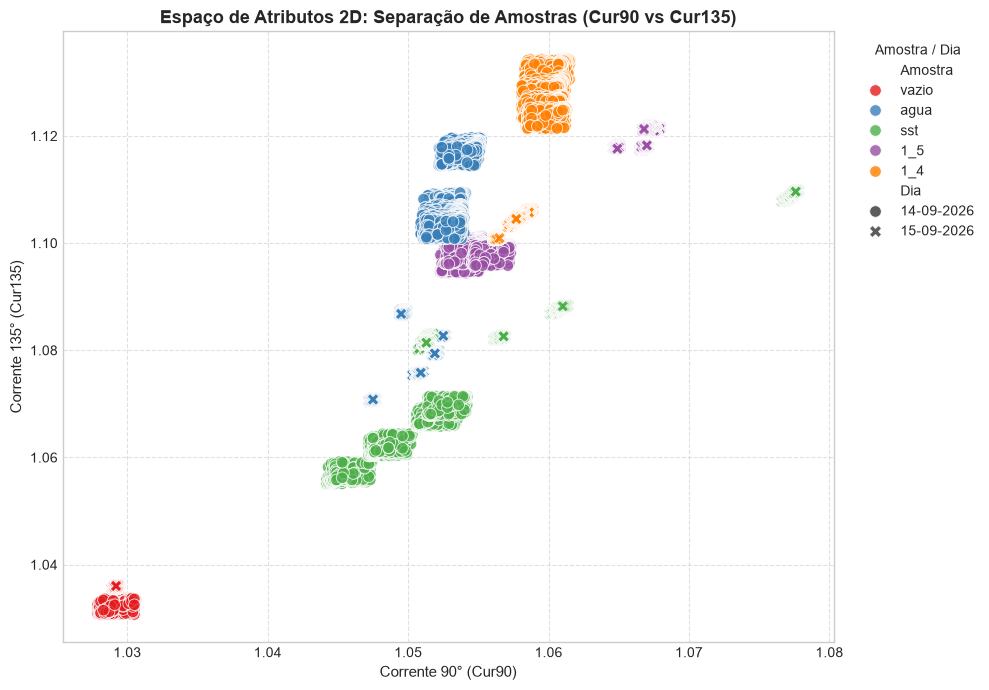

In [8]:
fig, ax = plt.subplots(figsize=(10, 7))

# Gráfico de dispersão com elipses de confiança ou estilo KDE
sns.scatterplot(
    data=df, x='Cur90', y='Cur135', hue='Amostra', style='Dia',
    s=70, alpha=0.8, palette='Set1', ax=ax
)

ax.set_title('Espaço de Atributos 2D: Separação de Amostras (Cur90 vs Cur135)', fontsize=13, fontweight='bold')
ax.set_xlabel('Corrente 90° (Cur90)', fontsize=11)
ax.set_ylabel('Corrente 135° (Cur135)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(title='Amostra / Dia', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "espaco_atributos_2d.png", dpi=300, bbox_inches='tight')
plt.show()

### Comparação de Distribuição

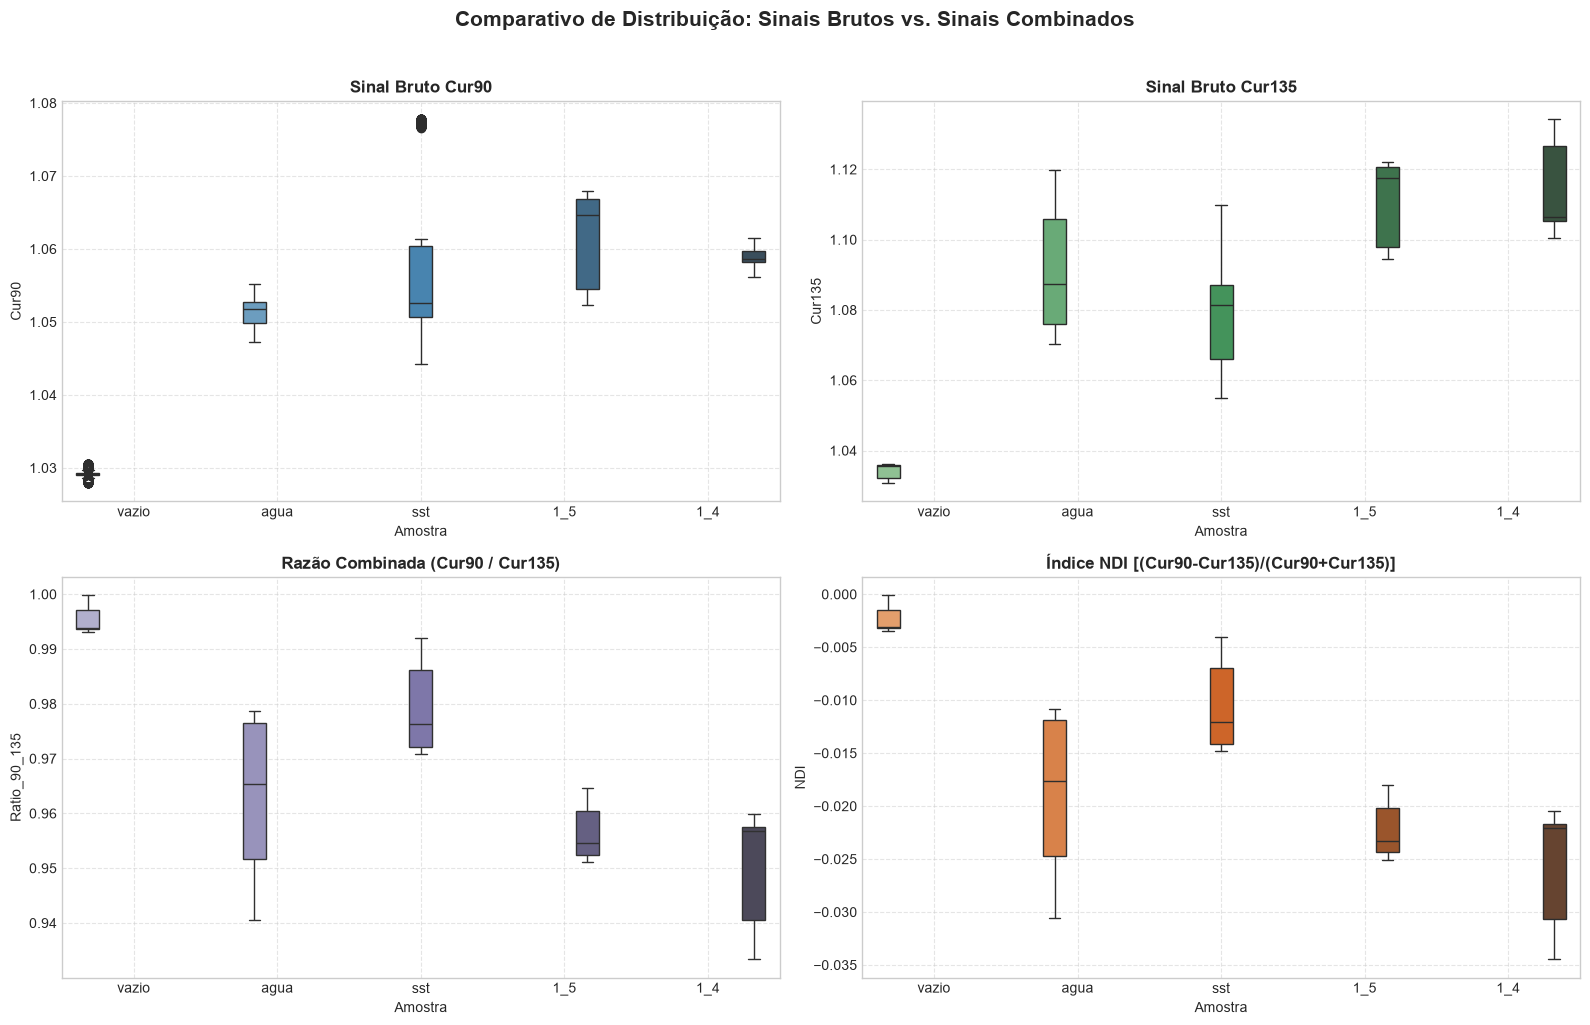

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Cur90 Bruto
sns.boxplot(data=df, x='Amostra', y='Cur90', ax=axes[0,0], palette='Blues_d', hue='Amostra')
axes[0,0].set_title('Sinal Bruto Cur90', fontweight='bold',)
axes[0,0].grid(True, linestyle='--', alpha=0.5)

# 2. Cur135 Bruto
sns.boxplot(data=df, x='Amostra', y='Cur135', ax=axes[0,1], palette='Greens_d', hue='Amostra')
axes[0,1].set_title('Sinal Bruto Cur135', fontweight='bold')
axes[0,1].grid(True, linestyle='--', alpha=0.5)

# 3. Razão (Cur90 / Cur135)
sns.boxplot(data=df, x='Amostra', y='Ratio_90_135', ax=axes[1,0], palette='Purples_d', hue='Amostra')
axes[1,0].set_title('Razão Combinada (Cur90 / Cur135)', fontweight='bold')
axes[1,0].grid(True, linestyle='--', alpha=0.5)

# 4. Índice NDI
sns.boxplot(data=df, x='Amostra', y='NDI', ax=axes[1,1], palette='Oranges_d', hue='Amostra')
axes[1,1].set_title('Índice NDI [(Cur90-Cur135)/(Cur90+Cur135)]', fontweight='bold')
axes[1,1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Comparativo de Distribuição: Sinais Brutos vs. Sinais Combinados', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribuicao_sinais_combinados.png", dpi=300, bbox_inches='tight')
plt.show()

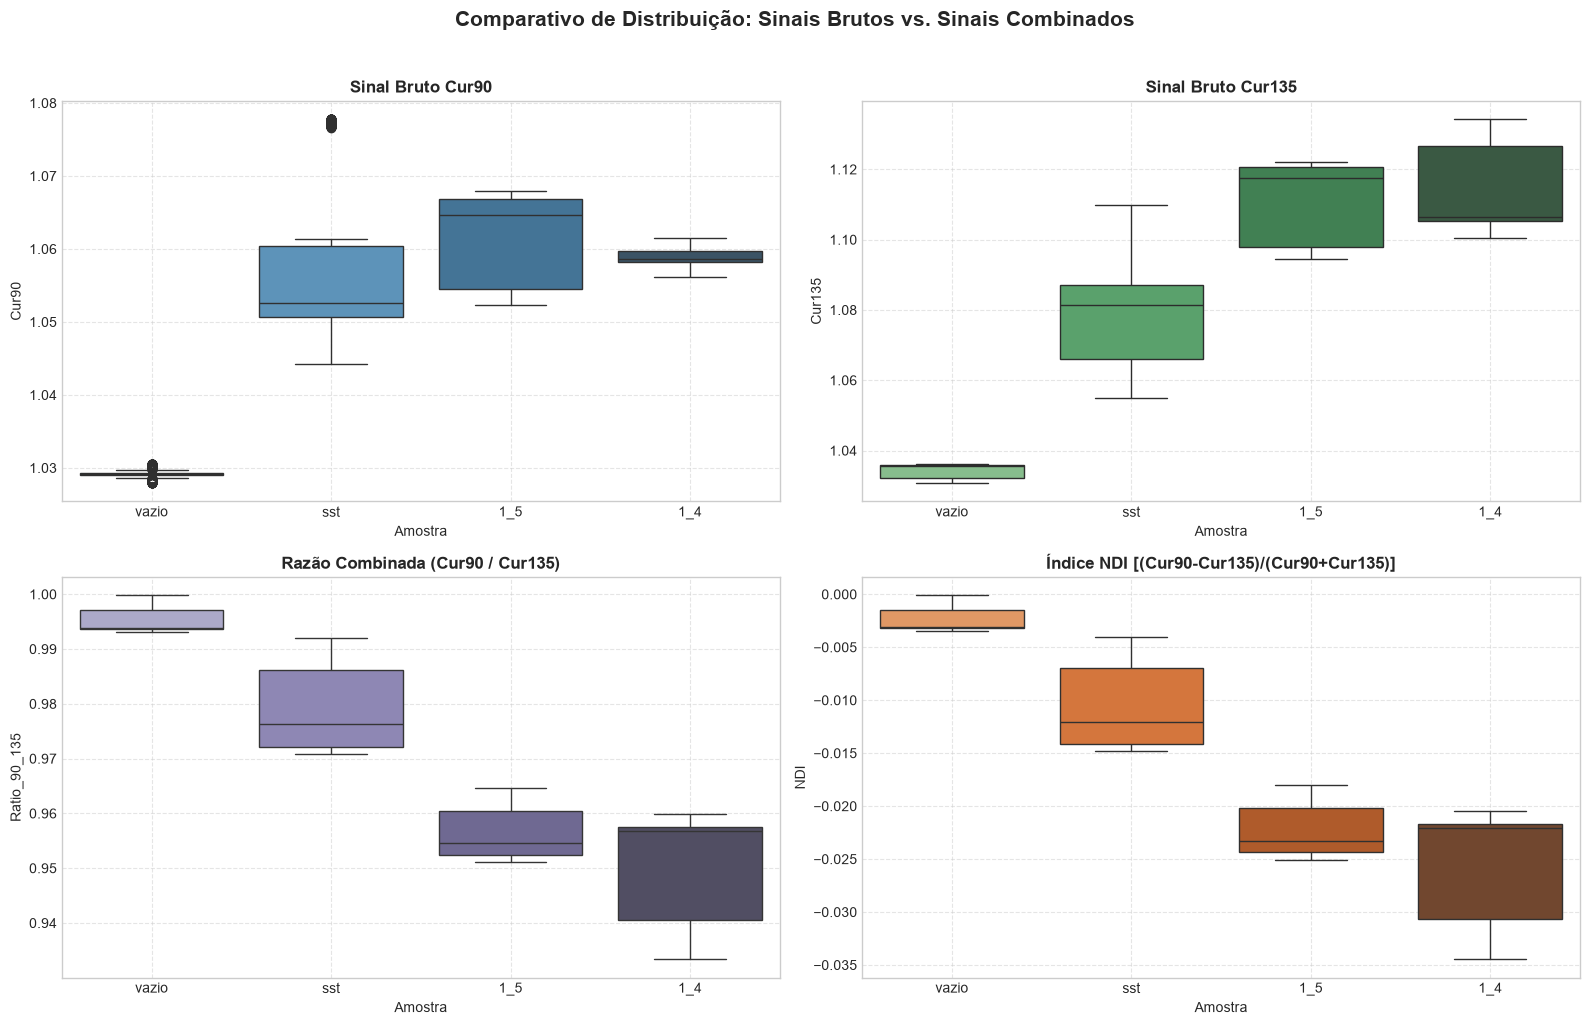

In [10]:
ordem_amostras = ['vazio', 'sst', '1_5', '1_4']

# Filtra a amostra 'agua' da base de dados
df_filtrado = df[df['Amostra'].astype(str) != 'agua'].copy()
df_filtrado['Amostra'] = pd.Categorical(
    df_filtrado['Amostra'].astype(str), 
    categories=ordem_amostras, 
    ordered=True
)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Mapeamento dos gráficos para iterar de forma limpa
configuracoes = [
    (axes[0,0], 'Cur90', 'Blues_d', 'Sinal Bruto Cur90'),
    (axes[0,1], 'Cur135', 'Greens_d', 'Sinal Bruto Cur135'),
    (axes[1,0], 'Ratio_90_135', 'Purples_d', 'Razão Combinada (Cur90 / Cur135)'),
    (axes[1,1], 'NDI', 'Oranges_d', 'Índice NDI [(Cur90-Cur135)/(Cur90+Cur135)]')
]

for ax, col, paleta, titulo in configuracoes:
    sns.boxplot(
        data=df_filtrado, 
        x='Amostra', 
        y=col, 
        order=ordem_amostras,
        hue='Amostra',
        dodge=False,  # Garante alinhamento perfeito no centro de cada tick
        palette=paleta, 
        ax=ax
    )
    ax.set_title(titulo, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xlabel('Amostra')
    
    # Remove legenda repetida gerada pelo hue
    if ax.get_legend() is not None:
        ax.get_legend().remove()

plt.suptitle('Comparativo de Distribuição: Sinais Brutos vs. Sinais Combinados', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribuicao_sinais_combinados_se_agua.png", dpi=300, bbox_inches='tight')
plt.show()

### Curva de Calibração Unificada

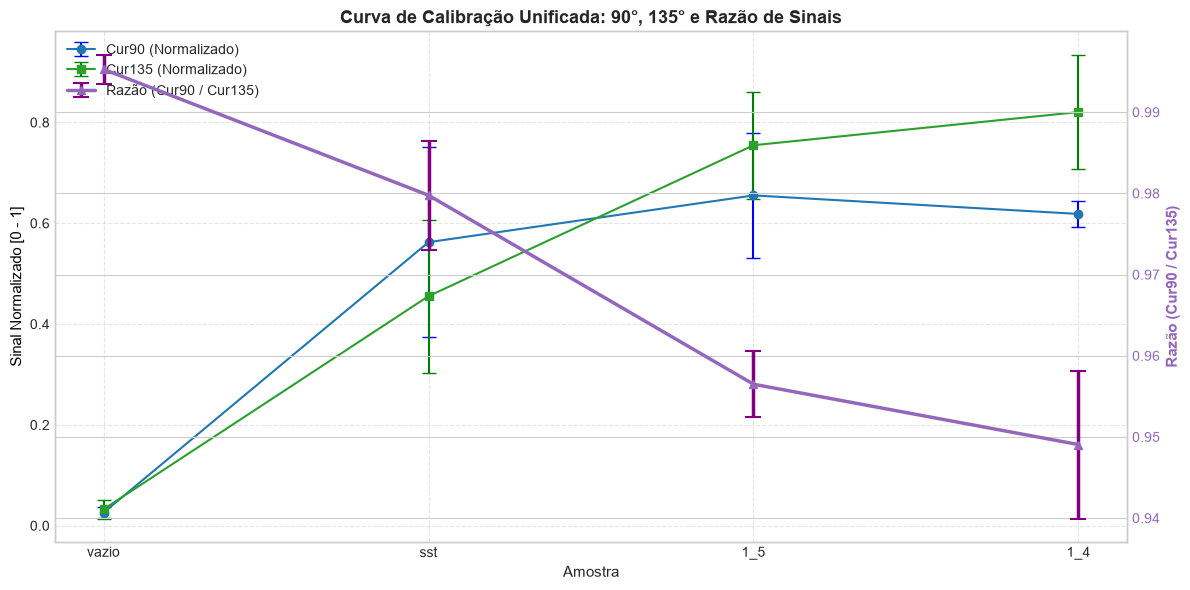

In [11]:
ordem_amostras = ['vazio', 'sst', '1_5', '1_4']

# 2. Filtrar a amostra 'agua' e recalcular as normalizações no subset limpo
df_calib = df[df['Amostra'].astype(str).isin(ordem_amostras)].copy()

# Recalcula min-max para garantir escala de 0 a 1 no subset filtrado
eps = 1e-9
df_calib['Cur90_norm'] = (df_calib['Cur90'] - df_calib['Cur90'].min()) / (df_calib['Cur90'].max() - df_calib['Cur90'].min() + eps)
df_calib['Cur135_norm'] = (df_calib['Cur135'] - df_calib['Cur135'].min()) / (df_calib['Cur135'].max() - df_calib['Cur135'].min() + eps)

# Define categoria ordenada
df_calib['Amostra'] = pd.Categorical(
    df_calib['Amostra'].astype(str), 
    categories=ordem_amostras, 
    ordered=True
)

# 3. Agrupamento estatístico com observed=True
df_comb_stats = df_calib.groupby('Amostra', observed=True).agg(
    m_90=('Cur90_norm', 'mean'), std_90=('Cur90_norm', 'std'),
    m_135=('Cur135_norm', 'mean'), std_135=('Cur135_norm', 'std'),
    m_ratio=('Ratio_90_135', 'mean'), std_ratio=('Ratio_90_135', 'std')
).reset_index()

# 4. Plotagem da curva unificada
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eixo 1: Sinais Normalizados (0 a 1)
ax1.errorbar(
    x=df_comb_stats['Amostra'], y=df_comb_stats['m_90'], yerr=df_comb_stats['std_90'],
    fmt='-o', color='tab:blue', ecolor='blue', capsize=5, elinewidth=1.5, label='Cur90 (Normalizado)'
)
ax1.errorbar(
    x=df_comb_stats['Amostra'], y=df_comb_stats['m_135'], yerr=df_comb_stats['std_135'],
    fmt='-s', color='tab:green', ecolor='green', capsize=5, elinewidth=1.5, label='Cur135 (Normalizado)'
)
ax1.set_ylabel('Sinal Normalizado [0 - 1]', color='black', fontsize=11)
ax1.set_xlabel('Amostra', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)

# Eixo 2 (Eixo Y Duplo): Razão de Sinal no mesmo gráfico
ax2 = ax1.twinx()
ax2.errorbar(
    x=df_comb_stats['Amostra'], y=df_comb_stats['m_ratio'], yerr=df_comb_stats['std_ratio'],
    fmt='-^', color='tab:purple', ecolor='purple', linewidth=2.5, capsize=6, capthick=1.5, label='Razão (Cur90 / Cur135)'
)
ax2.set_ylabel('Razão (Cur90 / Cur135)', color='tab:purple', fontsize=11, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='tab:purple')

# Unificação de legendas
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Curva de Calibração Unificada: 90°, 135° e Razão de Sinais', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "curva_calibracao_unificada_duplo_eixo.png", dpi=300, bbox_inches='tight')
plt.show()

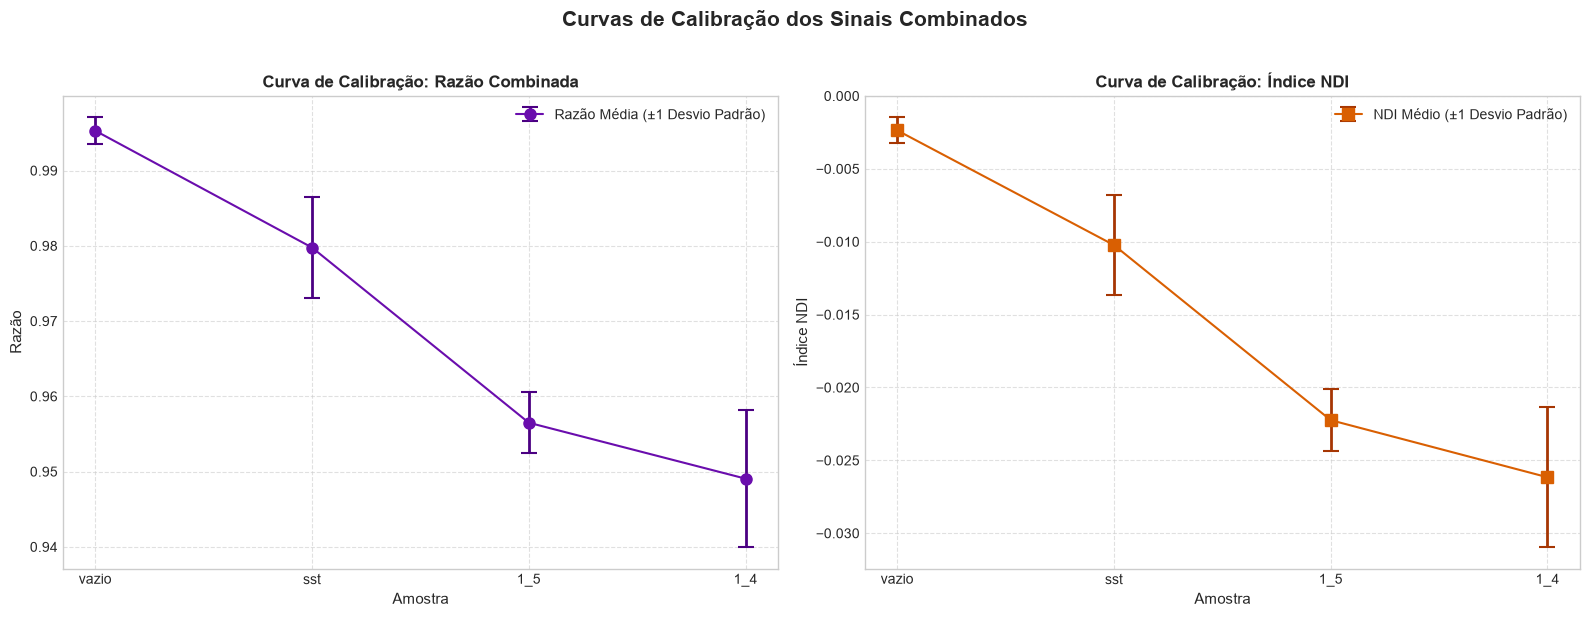

In [12]:
ordem_amostras = ['vazio', 'sst', '1_5', '1_4']

# 2. Filtrar dados excluindo 'agua' e redefinir a categoria ordenada
df_calib = df[df['Amostra'].astype(str).isin(ordem_amostras)].copy()
df_calib['Amostra'] = pd.Categorical(
    df_calib['Amostra'].astype(str), 
    categories=ordem_amostras, 
    ordered=True
)

# 3. Agrupamento estatístico (Média e Desvio Padrão)
df_stats = df_calib.groupby('Amostra', observed=True).agg(
    mean_ratio=('Ratio_90_135', 'mean'),
    std_ratio=('Ratio_90_135', 'std'),
    mean_ndi=('NDI', 'mean'),
    std_ndi=('NDI', 'std')
).reset_index()

# 4. Construção dos Gráficos das Curvas de Calibração
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Curva 1: Razão Combinada (Cur90 / Cur135) ---
axes[0].errorbar(
    x=df_stats['Amostra'], 
    y=df_stats['mean_ratio'], 
    yerr=df_stats['std_ratio'],
    fmt='-o', 
    color='#6a0dad', 
    ecolor='#4b0082', 
    elinewidth=2, 
    capsize=6, 
    capthick=1.5,
    markersize=8,
    label='Razão Média (±1 Desvio Padrão)'
)
axes[0].set_title('Curva de Calibração: Razão Combinada', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Amostra', fontsize=11)
axes[0].set_ylabel('Razão', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='best')

# --- Curva 2: Índice NDI ---
axes[1].errorbar(
    x=df_stats['Amostra'], 
    y=df_stats['mean_ndi'], 
    yerr=df_stats['std_ndi'],
    fmt='-s', 
    color='#d95f02', 
    ecolor='#a63603', 
    elinewidth=2, 
    capsize=6, 
    capthick=1.5,
    markersize=8,
    label='NDI Médio (±1 Desvio Padrão)'
)
axes[1].set_title('Curva de Calibração: Índice NDI', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Amostra', fontsize=11)
axes[1].set_ylabel('Índice NDI', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='best')

plt.suptitle('Curvas de Calibração dos Sinais Combinados', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

# Salva a figura na pasta de calibração
plt.savefig(FIGURES_DIR / "curvas_calibracao_ratio_ndi.png", dpi=300, bbox_inches='tight')
plt.show()

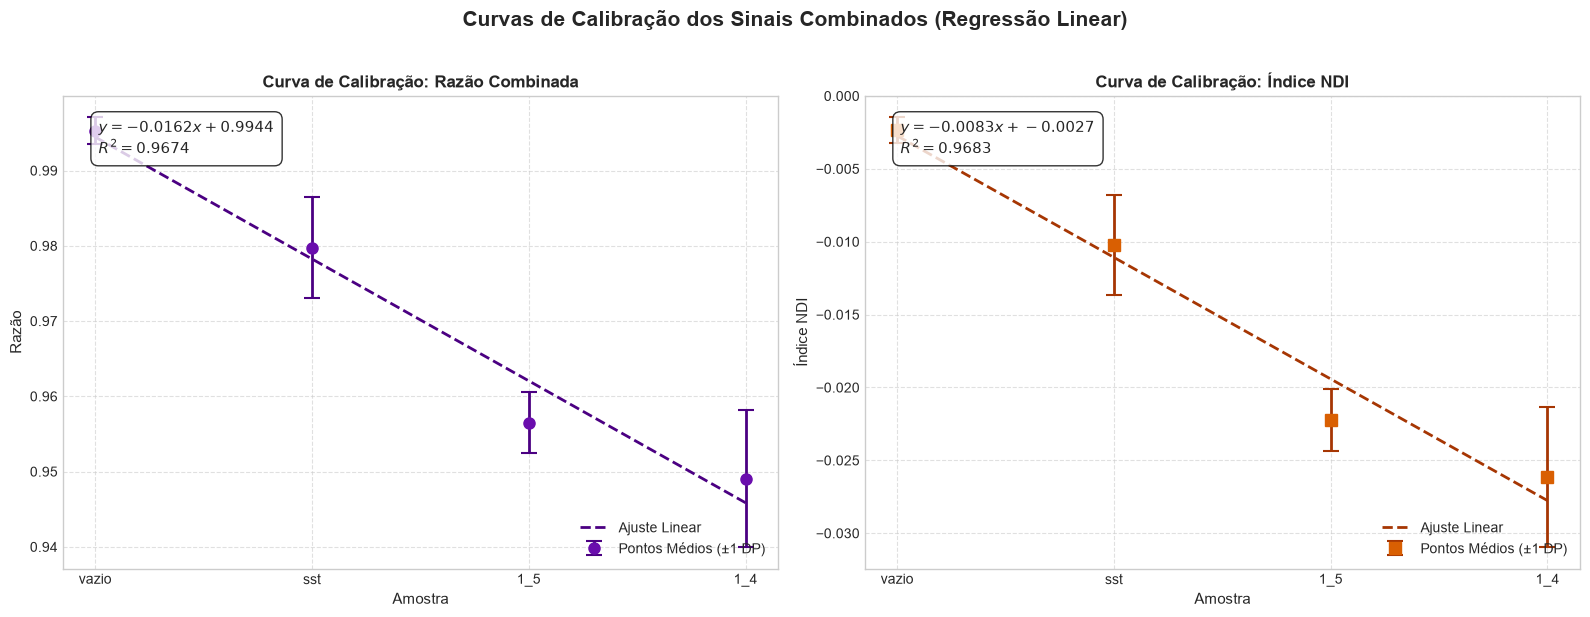

In [14]:
df_stats = df_calib.groupby('Amostra', observed=True).agg(
    mean_ratio=('Ratio_90_135', 'mean'),
    std_ratio=('Ratio_90_135', 'std'),
    mean_ndi=('NDI', 'mean'),
    std_ndi=('NDI', 'std')
).reset_index()

x_num = np.arange(len(df_stats))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Curva 1: Razão Combinada ---
# Ajuste linear
res_ratio = linregress(x_num, df_stats['mean_ratio'])
r2_ratio = res_ratio.rvalue**2
y_fit_ratio = res_ratio.slope * x_num + res_ratio.intercept

axes[0].errorbar(
    x=x_num, 
    y=df_stats['mean_ratio'], 
    yerr=df_stats['std_ratio'],
    fmt='o', color='#6a0dad', ecolor='#4b0082', elinewidth=2, 
    capsize=6, capthick=1.5, markersize=8, label='Pontos Médios (±1 DP)'
)
axes[0].plot(x_num, y_fit_ratio, '--', color='#4b0082', linewidth=2, label='Ajuste Linear')

eq_ratio = f'$y = {res_ratio.slope:.4f}x + {res_ratio.intercept:.4f}$\n$R^2 = {r2_ratio:.4f}$'
axes[0].text(0.05, 0.95, eq_ratio, transform=axes[0].transAxes, fontsize=11,
             verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8))

axes[0].set_xticks(x_num)
axes[0].set_xticklabels(df_stats['Amostra'])
axes[0].set_title('Curva de Calibração: Razão Combinada', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Amostra', fontsize=11)
axes[0].set_ylabel('Razão', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='lower right')

# --- Curva 2: Índice NDI ---
# Ajuste linear
res_ndi = linregress(x_num, df_stats['mean_ndi'])
r2_ndi = res_ndi.rvalue**2
y_fit_ndi = res_ndi.slope * x_num + res_ndi.intercept

axes[1].errorbar(
    x=x_num, 
    y=df_stats['mean_ndi'], 
    yerr=df_stats['std_ndi'],
    fmt='s', color='#d95f02', ecolor='#a63603', elinewidth=2, 
    capsize=6, capthick=1.5, markersize=8, label='Pontos Médios (±1 DP)'
)
axes[1].plot(x_num, y_fit_ndi, '--', color='#a63603', linewidth=2, label='Ajuste Linear')

eq_ndi = f'$y = {res_ndi.slope:.4f}x + {res_ndi.intercept:.4f}$\n$R^2 = {r2_ndi:.4f}$'
axes[1].text(0.05, 0.95, eq_ndi, transform=axes[1].transAxes, fontsize=11,
             verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8))

axes[1].set_xticks(x_num)
axes[1].set_xticklabels(df_stats['Amostra'])
axes[1].set_title('Curva de Calibração: Índice NDI', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Amostra', fontsize=11)
axes[1].set_ylabel('Índice NDI', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='lower right')

plt.suptitle('Curvas de Calibração dos Sinais Combinados (Regressão Linear)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "curvas_calibracao_ratio_ndi.png", dpi=300, bbox_inches='tight')
plt.show()